# 함정 7. QAT 중 BN 통계를 계속 움직이면 무너진다

## BN 동결 플래그와 고정 가중치의 코드 안정성

가중치와 observer 범위를 고정한 작은 Conv–BN 레이어에 같은 합성 배치들을 입력한다. 입력 분포는 스텝에 따라 달라지며, 실험에서 바꾸는 변수는 BN 동결 시점 {처음, 중간, 동결 안 함}이다. 매 스텝 `layer.train()`을 호출해도 동결된 BN 통계가 유지되는지 검증한다.

이 첫 비교에서는 optimizer 업데이트 없이 BN 상태의 영향을 확인한다. 학습된 모델의 분류 정확도는 뒤쪽 절에서 다룬다. 아래의 코드 변경률은 running 통계로 접은 가중치의 정수 코드를 비교한 값이다. 시드 0 하나로 실행한다. [학습 가이드](../docs/README.md#함정-7-qat-중-bn-통계를-계속-움직이면-무너진다).


In [1]:
import json
import os
import platform
import random
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
RESULTS = ROOT / "runs" / "m2"
FIGURES = ROOT / "docs" / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(RESULTS / ".matplotlib"))

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
generator = torch.Generator(device=DEVICE).manual_seed(SEED)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "svg.fonttype": "none", "svg.hashsalt": "quant-pitfalls"})
RUN_INFO = {"seed": SEED, "seeds": 1, "python": platform.python_version(), "torch": torch.__version__, "device": DEVICE,
            "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None, "runtime_seconds": None}
STARTED = time.monotonic()
run_display = display(RUN_INFO, display_id=True)


{'seed': 0,
 'seeds': 1,
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'device': 'cuda',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 1.761}

In [2]:
from copy import deepcopy
from torch import nn
from quant_pitfalls.layers.conv_bn import QuantConvBn2d
from quant_pitfalls.quant.fake_quant import FakeQuantize
from quant_pitfalls.quant.uniform import UniformSpec, quantize

spec = UniformSpec(4)
conv = nn.Conv2d(3, 8, 3, padding=1, bias=False).to(DEVICE, dtype=torch.float64)
bn = nn.BatchNorm2d(8).to(DEVICE, dtype=torch.float64)
base = QuantConvBn2d.from_float(conv, bn, weight_fq=FakeQuantize(spec, axis=0))
initial_weight, _ = base.folded_weight_and_bias()
base.weight_fq(initial_weight)
base.weight_fq.enable_observer(False)
batches = [torch.randn(32, 3, 8, 8, device=DEVICE, dtype=torch.float64, generator=generator) * (0.5 + 0.15 * step)
           + 0.2 * np.sin(step / 3) for step in range(24)]
curves, summaries = {}, []
for label, freeze_at in [("Freeze from start", 0), ("Freeze at step 12", 12), ("Never freeze", None)]:
    layer = deepcopy(base)
    initial_var = layer.bn.running_var.clone()
    previous_codes = quantize(initial_weight, layer.weight_fq.alpha, spec, axis=0)
    curve = []
    with torch.no_grad():
        for step, batch in enumerate(batches):
            if freeze_at == step:
                layer.freeze_bn_stats()
            layer.train()
            layer(batch)
            running_weight = layer.conv.weight * (layer.bn.weight / torch.sqrt(layer.bn.running_var + layer.bn.eps)).reshape(-1, 1, 1, 1)
            codes = quantize(running_weight, layer.weight_fq.alpha, spec, axis=0)
            change = float((codes != previous_codes).double().mean() * 100)
            curve.append({"step": step, "running_var_mean": float(layer.bn.running_var.mean()), "code_change_pct": change,
                          "bn_training": layer.bn.training})
            previous_codes = codes
    if freeze_at is not None:
        assert all(not r["bn_training"] and r["code_change_pct"] == 0 for r in curve[freeze_at:])
    curves[label] = curve
    summaries.append({"method": label, "freeze_at": freeze_at, "maximum_running_var_change": float((layer.bn.running_var - initial_var).abs().max()),
                      "bn_updates": int(layer.bn.num_batches_tracked), "last_step_code_change_pct": curve[-1]["code_change_pct"]})
for row in summaries:
    print(row)


{'method': 'Freeze from start', 'freeze_at': 0, 'maximum_running_var_change': 0.0, 'bn_updates': 0, 'last_step_code_change_pct': 0.0}
{'method': 'Freeze at step 12', 'freeze_at': 12, 'maximum_running_var_change': 0.31809438392433476, 'bn_updates': 12, 'last_step_code_change_pct': 0.0}
{'method': 'Never freeze', 'freeze_at': None, 'maximum_running_var_change': 1.806877472658651, 'bn_updates': 24, 'last_step_code_change_pct': 11.574074074074073}


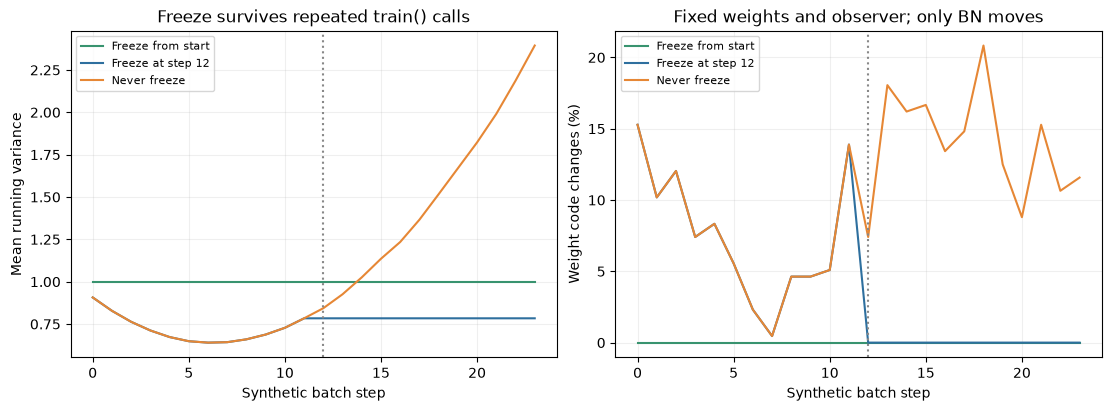

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for (label, curve), color in zip(curves.items(), ["#38936F", "#2E6F9E", "#E68735"]):
    steps = [r["step"] for r in curve]
    axes[0].plot(steps, [r["running_var_mean"] for r in curve], label=label, color=color)
    axes[1].plot(steps, [r["code_change_pct"] for r in curve], label=label, color=color)
axes[0].set(xlabel="Synthetic batch step", ylabel="Mean running variance", title="Freeze survives repeated train() calls")
axes[1].set(xlabel="Synthetic batch step", ylabel="Weight code changes (%)", title="Fixed weights and observer; only BN moves")
for ax in axes:
    ax.axvline(12, color="#888888", linestyle=":")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.savefig(FIGURES / "07_bn-stats-in-qat.svg", metadata={"Date": None})
fig.savefig(RESULTS / "07_bn-stats-in-qat.png", dpi=140)
plt.show()
report = {"weights_fixed": True, "observer_frozen": True, "batch_size": 32, "summaries": summaries, "curves": curves}


In [4]:
if DEVICE == "cuda":
    torch.cuda.synchronize()
report["run"] = {**RUN_INFO, "runtime_seconds": round(time.monotonic() - STARTED, 3)}
(RESULTS / "07_bn-stats-in-qat.json").write_text(json.dumps(report, indent=2) + "\n")
run_display.update(report["run"])
print("Saved results: runs/m2/07_bn-stats-in-qat.json")


Saved results: runs/m2/07_bn-stats-in-qat.json


## 학습된 QAT 모델의 BN 동결 시점

같은 시드의 float 체크포인트에서 BN 동결 시점과 배치 크기의 영향을 비교한다. 동결 시점을 비교할 때는 배치 크기를, 배치 크기를 비교할 때는 동결 시점을 고정한다. 시드 0·1·2의 손실·정확도·코드 변경률 기록을 읽는다.

기본 재현 명령은 저장소의 측정 기록을 사용한다. 새로운 학습 결과를 만들려면 [재현 방법](../docs/reproduction.md)의 체크포인트·학습 모드를 참고한다.


In [5]:
import json
import os
import platform
import time
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
RESULTS = ROOT / 'runs' / 'm3'
FIGURES = ROOT / 'docs' / 'figures'
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(RESULTS / '.matplotlib'))
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display, Markdown
plt.rcParams.update({'font.family':'DejaVu Sans','svg.fonttype':'none','svg.hashsalt':'quant-pitfalls'})
STARTED = time.perf_counter()
RUN_INFO = {'seeds':[0,1,2], 'python':platform.python_version(), 'torch':torch.__version__,
            'gpu':torch.cuda.get_device_name() if torch.cuda.is_available() else None, 'runtime_seconds':None}
INFO_HANDLE = display(RUN_INFO, display_id=True)
from quant_pitfalls.results import load_results
REPORT, DATA_SOURCE = load_results(ROOT, 'm3')
print('Training numerical input:', DATA_SOURCE)
print('Recorded training environment:', REPORT.get('reports', {}).get('float-baseline-s0', {}).get('environment'))
READY = REPORT.get('state') == 'complete'
if not READY:
    print('Selected training measurements are incomplete; plots are omitted.')

def save_figure(fig, name):
    fig.savefig(FIGURES / (name + '.svg'), bbox_inches='tight', metadata={'Date':None})
    fig.savefig(RESULTS / (name + '.png'), bbox_inches='tight', dpi=140)
    plt.show()

{'seeds': [0, 1, 2],
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 1.692,
 'training_status': 'complete'}

Training numerical input: docs/results/m3.json.gz
Recorded training environment: {'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeForce RTX 5090'}


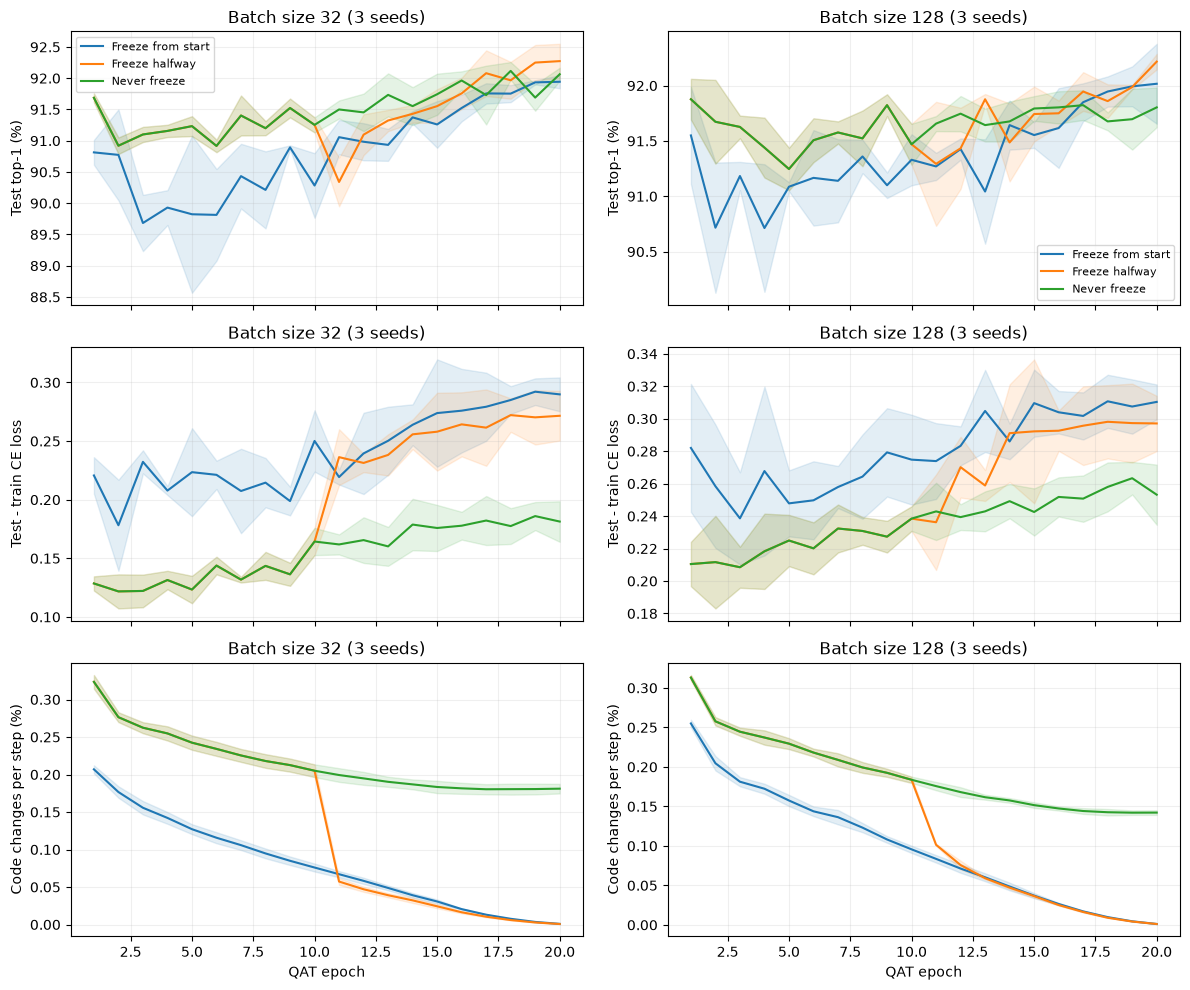

In [6]:
if READY:
    fig,axes=plt.subplots(3,2,figsize=(12,10),sharex=True)
    for col,batch in enumerate((32,128)):
        for frozen,label in (('0','Freeze from start'),('0.5','Freeze halfway'),('1','Never freeze')):
            prefix='qat-w4a8-pc-mse-staged-uniform-nearest-fp32' if batch==128 and frozen=='0.5' else f'nb07-bs{batch}-freeze{frozen}'
            histories=[REPORT['reports'][f'{prefix}-s{s}']['history'] for s in (0,1,2)]
            curves=(np.array([[h['test_top1'] for h in items] for items in histories]),
                    np.array([[h['test_loss']-h['train_ce_loss'] for h in items] for items in histories]),
                    np.array([[np.mean(h['weight_code_change_fractions'])*100 for h in items] for items in histories]))
            for row,curve in enumerate(curves):
                mean,std=curve.mean(0),curve.std(0,ddof=1)
                line=axes[row,col].plot(np.arange(1,21),mean,label=label)[0]
                axes[row,col].fill_between(np.arange(1,21),mean-std,mean+std,color=line.get_color(),alpha=.12)
                axes[row,col].set_title(f'Batch size {batch} (3 seeds)')
                axes[row,col].set_ylabel(('Test top-1 (%)','Test - train CE loss','Code changes per step (%)')[row])
                axes[row,col].grid(alpha=.2)
        axes[0,col].legend(fontsize=8)
        axes[2,col].set_xlabel('QAT epoch')
    fig.tight_layout()
    save_figure(fig,'07_bn-freeze-training')

In [7]:
RUN_INFO['runtime_seconds'] = round(time.perf_counter()-STARTED, 3)
RUN_INFO['training_status'] = REPORT['state']
INFO_HANDLE.update(RUN_INFO)

## 직접 확인하기

한 배치 크기를 고정하고 BN 동결 시점만 다른 학습 곡선을 비교해 보자. 정확도와 코드 변경률이 같은 방향으로 움직이는지 확인하자.
